# 05 - Heavy baselines (Week 7)

**resnet50** and **vgg16** on the v1 **original** and v1 **clean** splits, with the same `src.train.run()` recipe as the
light models (AdamW, warm-up + cosine, label smoothing 0.1, class weights, seed 42). As CLAUDE.md requires for heavy models,
they use learning rate 3e-4 and a frozen backbone for the first 2 epochs. Stopping rule (my choice): max 12 epochs,
patience 5, and stop as soon as val accuracy >= 0.92 (same rule as the last 4 light runs);
vgg16 on v1_original stops at 0.90 (my decision, see Settings).

New this week in `src/train.py`:
- **resume**: `last.pt` is saved after every epoch and deleted when the run finishes; a stopped run continues where it was.
- **probe()**: measures GPU memory and speed before a long run (random images, backbone unfrozen = worst case).
- **runs_table()**: one table of every training run (light + heavy).

The long runs were started from the terminal (`python -u -m src.train <model> <split> --epochs 12 --target-acc 0.92`)
so they could run in the background. This notebook calls the same `run()`: finished runs are skipped, so executing it
only reloads the results.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
import torch
from IPython.display import Image as ShowImage, display
from src import train
from src.models import MODELS

SPLITS = Path('outputs/splits')
RUNS = Path('outputs/runs')
print('torch', torch.__version__, '| CUDA', torch.cuda.is_available(),
      '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
pd.DataFrame(MODELS).T

D:\Brain-Tumor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.14.1+cu126 | CUDA True | NVIDIA GeForce GTX 1650 Ti


,batch,img_size,heavy,amp
mobilenetv3_small_100,48,224,False,True
efficientnet_b0,32,224,False,False
resnet50,24,224,True,False
inception_v3,24,299,True,True
densenet121,16,224,True,True
vgg16,16,224,True,True


## Settings

In [2]:
VERSIONS = ['v1']                         # v1 only (my decision: the dataset with the duplicates)
SPLIT_TYPES = ['clean', 'original']
MODELS_TO_RUN = ['resnet50', 'vgg16']
EPOCHS = 12
PATIENCE = 5
TARGET_ACC = 0.92
# Exception (my decision during Week 7, after vgg16 v1_clean needed 10 epochs to reach 0.92): the last run,
# vgg16 on v1_original, stops at val acc >= 0.90 instead.
TARGET_OVERRIDE = {('vgg16', 'v1_original'): 0.90}
# That run was then STOPPED BY HAND after epoch 5 (my decision; val acc 0.897). It was closed with a resume that
# trained 0 epochs, and its config.json says stopped_by = 'user_stop' (max_epochs stays 12, as planned).
# Because it is finished, the loop below skips it.

## 1. Memory and speed probe (measured before training)
Saved in `outputs/runs/probe_week7.json` by `train.probe()`. The float32 rows were measured to compare the two precisions;
**training uses each model's own setting from `src/models.py`**: vgg16 float16, resnet50 float32 (changed during
Week 7, see section 2). `reserved_gpu_mb` above 4,096 means
Windows moved the extra into normal RAM (slower, but no out-of-memory error).

In [3]:
probes = pd.DataFrame(json.load(open(RUNS / 'probe_week7.json')))
probes

,model,batch,img_size,amp,train_s_per_batch,peak_gpu_mb,reserved_gpu_mb,frozen_s_per_batch,eval_s_per_batch,oom
0,resnet50,24,224,True,2.7286,1762.0,1830.0,1.0809,0.3048,False
1,vgg16,16,224,True,2.4595,2897.6,3212.0,0.7321,0.7295,False
2,resnet50,24,224,False,2.2683,3021.7,3240.0,0.9403,0.1120,False
3,vgg16,16,224,False,1.2493,3551.4,4532.0,0.4246,0.4243,False
4,vgg16,8,224,False,0.4137,3256.9,3644.0,0.0997,0.0994,False


Time estimate per run = per epoch (train batches x s/batch + val batches x s/eval-batch), with the 2 frozen epochs
at the faster frozen speed. Shown for 3 epochs (the earliest the 0.92 target can stop a heavy run, after unfreezing)
and for all 12. Start-up (~1-3 min) is not included.

In [4]:
sizes = {}
for split_type in SPLIT_TYPES:
    t = pd.read_csv(SPLITS / f'v1_split_{split_type}.csv')
    sizes[f'v1_{split_type}'] = ((t['split'] == 'train').sum(), (t['split'] == 'val').sum())
rows = []
for model_name in MODELS_TO_RUN:
    p = probes[(probes['model'] == model_name) & (probes['batch'] == MODELS[model_name]['batch'])
               & (probes['amp'] == MODELS[model_name]['amp'])].iloc[0]
    for split, (n_train, n_val) in sizes.items():
        rows.append({'model': model_name, 'split': split, 'train': n_train, 'val': n_val,
                     'est_min_3_epochs': round(train.estimate_minutes(p, n_train, n_val, 3), 1),
                     'est_min_12_epochs': round(train.estimate_minutes(p, n_train, n_val, EPOCHS), 1)})
estimates = pd.DataFrame(rows)
estimates

,model,split,train,val,est_min_3_epochs,est_min_12_epochs
0,resnet50,v1_clean,2426,520,7.1,41.8
1,resnet50,v1_original,4855,857,14.2,83.5
2,vgg16,v1_clean,2426,520,11.1,70.4
3,vgg16,v1_original,4855,857,21.8,139.5


## 2. Smoke test (50 images, 1 epoch)
Already run from the terminal before training. These calls are skipped because the runs are finished; the check
below reads their files.

In [5]:
for model_name in MODELS_TO_RUN:
    cfg = train.run(model_name, 'smoke', SPLITS / 'v1_split_clean.csv', epochs=1, subset=50)
    smoke_dir = RUNS / 'smoke' / model_name
    print(f'{model_name}: files {sorted(p.name for p in smoke_dir.iterdir())}, '
          f'NaN at epoch {cfg["amp_disabled_at_epoch"]} -> float32, peak GPU {cfg["peak_gpu_mb"]} MB')

skipped smoke/resnet50: already finished
resnet50: files ['best.pt', 'config.json', 'history.csv'], NaN at epoch 1 -> float32, peak GPU 2570.7 MB
skipped smoke/vgg16: already finished
vgg16: files ['best.pt', 'config.json', 'history.csv'], NaN at epoch 1 -> float32, peak GPU 2975.0 MB


Smoke-test finding: resnet50 got NaN in float16 at epoch 1. Before the NaN guard noticed it, the NaN had already
been written into the BatchNorm running statistics, so the smoke checkpoint is broken (checked below). vgg16 has no
BatchNorm, so its float32 fall-back is safe.

In the real runs resnet50 hit float16 NaN again: v1_clean at epoch 2 (BatchNorm stats stayed clean, run kept, float32
from epoch 2 on) and v1_original at epoch 1 (BatchNorm stats corrupted, val loss NaN -> stopped and moved to
`outputs/runs/failed/`). Decision: resnet50 trains in **float32** (`amp=False` in `src/models.py`, like efficientnet_b0);
v1_original was re-run from scratch.

In [6]:
bad_dir = RUNS / 'failed' / 'v1_original_resnet50_fp16_nan'
print(pd.read_csv(bad_dir / 'history.csv')[['epoch', 'train_loss', 'val_loss', 'val_acc', 'amp']])
sd = torch.load(bad_dir / 'last.pt', weights_only=False)['model']
print('non-finite tensors in the failed run:', sum(1 for v in sd.values() if v.is_floating_point() and not torch.isfinite(v).all()))

   epoch  train_loss  val_loss   val_acc    amp
0      1    1.334155       NaN  0.231039  False


non-finite tensors in the failed run: 78


In [7]:
for model_name in MODELS_TO_RUN:
    sd = torch.load(RUNS / 'smoke' / model_name / 'best.pt', weights_only=False)['model']
    bad = [k for k, v in sd.items() if v.is_floating_point() and not torch.isfinite(v).all()]
    print(f'{model_name}: {len(bad)} non-finite tensors in the smoke checkpoint', bad[:2])

resnet50: 84 non-finite tensors in the smoke checkpoint ['layer2.0.bn1.running_mean', 'layer2.0.bn1.running_var']


vgg16: 0 non-finite tensors in the smoke checkpoint []


## 3. Training (one run at a time; finished runs are skipped)
Order: smaller split first, faster model first.

In [8]:
run_dirs = []
for version in VERSIONS:
    for model_name in MODELS_TO_RUN:
        for split_type in SPLIT_TYPES:
            split_name = f'{version}_{split_type}'
            train.run(model_name, split_name, SPLITS / f'{version}_split_{split_type}.csv',
                      epochs=EPOCHS, patience=PATIENCE,
                      target_acc=TARGET_OVERRIDE.get((model_name, split_name), TARGET_ACC))
            run_dir = RUNS / split_name / model_name
            run_dirs.append(run_dir)
            s = train.run_summary(run_dir)
            print(f'==> {split_name}/{model_name}: val acc {s["val_acc"]:.4f}, val macro-F1 {s["val_macro_f1"]:.4f}, '
                  f'epochs {s["epochs_run"]} (best {s["best_epoch"]}), {s["train_time_min"]} min, '
                  f'peak GPU {s["peak_gpu_mb"]} MB')
            for w in train.health_check(run_dir):
                print('    WARNING:', w)

skipped v1_clean/resnet50: already finished
==> v1_clean/resnet50: val acc 0.9538, val macro-F1 0.9517, epochs 6 (best 6), 21.3 min, peak GPU 3021.7 MB
skipped v1_original/resnet50: already finished
==> v1_original/resnet50: val acc 0.9218, val macro-F1 0.9200, epochs 3 (best 3), 16.1 min, peak GPU 3022.3 MB
skipped v1_clean/vgg16: already finished
==> v1_clean/vgg16: val acc 0.9212, val macro-F1 0.9145, epochs 10 (best 10), 31.9 min, peak GPU 3550.6 MB
skipped v1_original/vgg16: already finished
==> v1_original/vgg16: val acc 0.8973, val macro-F1 0.8944, epochs 5 (best 5), 25.1 min, peak GPU 3550.6 MB


Checkpoint check: no NaN/Inf anywhere in the saved weights or BatchNorm statistics, and no `last.pt` left over.

In [9]:
for run_dir in run_dirs:
    sd = torch.load(run_dir / 'best.pt', weights_only=False)['model']
    bad = sum(1 for v in sd.values() if v.is_floating_point() and not torch.isfinite(v).all())
    print(f'{run_dir}: non-finite tensors {bad}, last.pt left {(run_dir / "last.pt").exists()}')

outputs\runs\v1_clean\resnet50: non-finite tensors 0, last.pt left False


outputs\runs\v1_original\resnet50: non-finite tensors 0, last.pt left False


outputs\runs\v1_clean\vgg16: non-finite tensors 0, last.pt left False


outputs\runs\v1_original\vgg16: non-finite tensors 0, last.pt left False


## 4. Estimated vs actual training time

In [10]:
actual = pd.DataFrame([train.run_summary(d) for d in run_dirs])[['split', 'model', 'epochs_run', 'train_time_min']]
estimates.merge(actual, on=['split', 'model'])

,model,split,train,val,est_min_3_epochs,est_min_12_epochs,epochs_run,train_time_min
0,resnet50,v1_clean,2426,520,7.1,41.8,6,21.3
1,resnet50,v1_original,4855,857,14.2,83.5,3,16.1
2,vgg16,v1_clean,2426,520,11.1,70.4,10,31.9
3,vgg16,v1_original,4855,857,21.8,139.5,5,25.1


## 5. Training curves

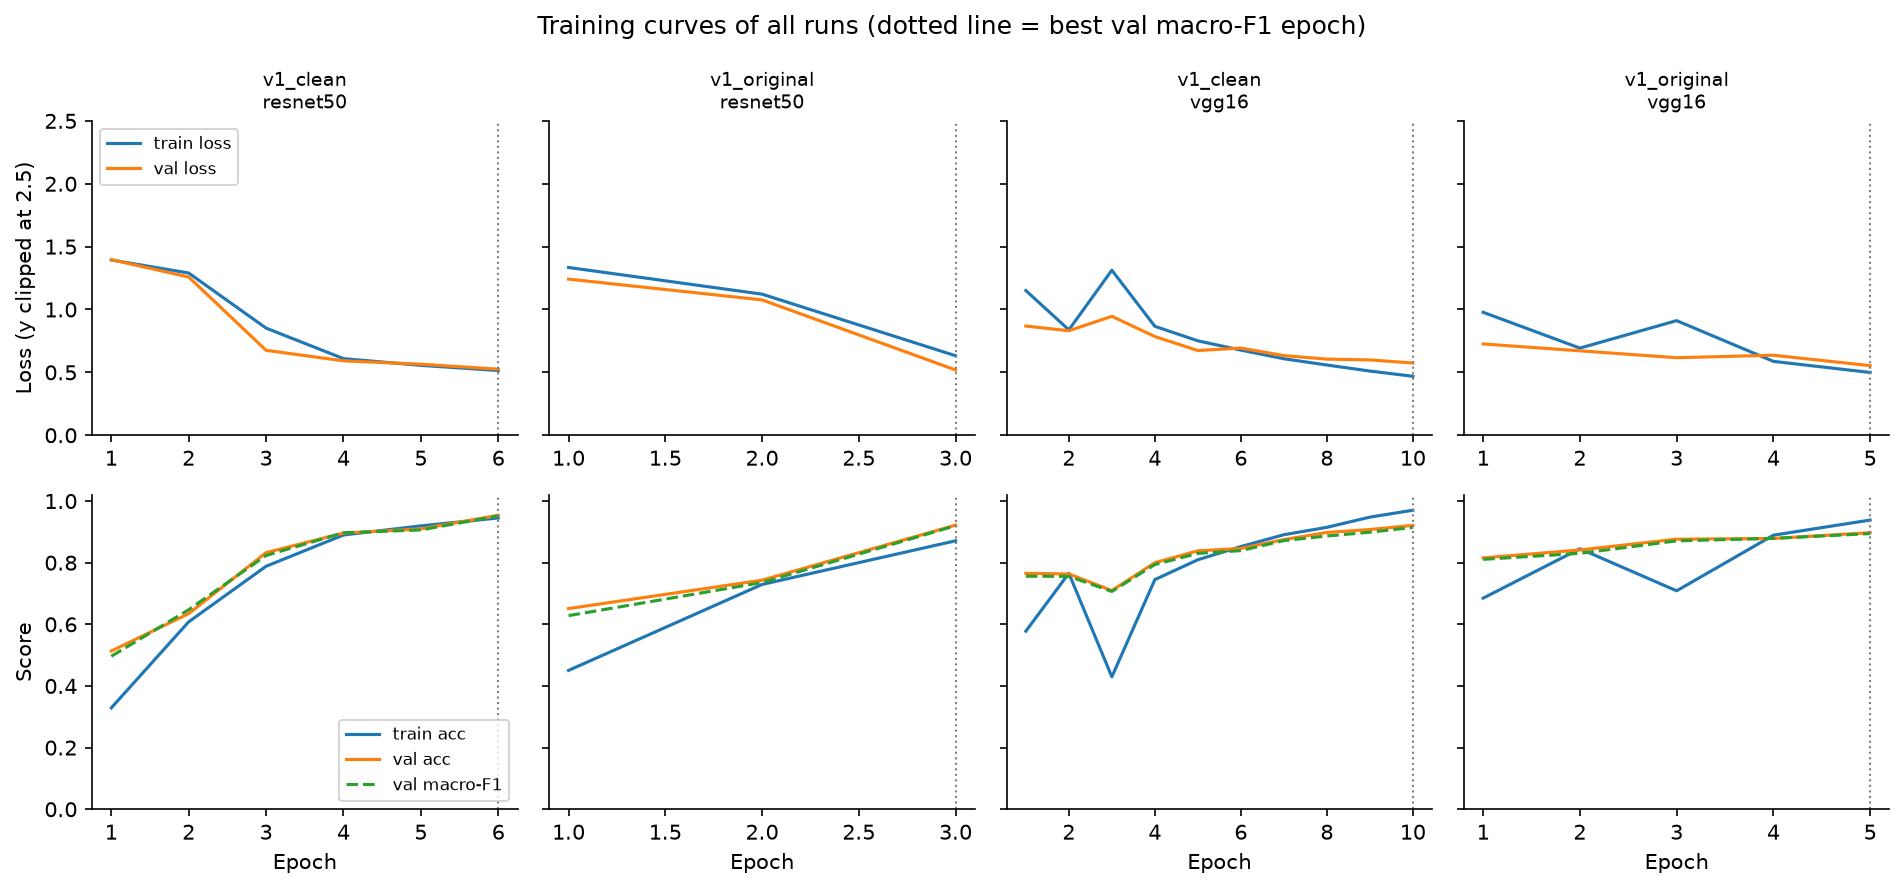

In [11]:
fig_path = train.plot_all_histories(run_dirs, 'outputs/plots/week7/heavy_runs_curves.png')
for run_dir in run_dirs:
    train.plot_history(run_dir, out_dir='outputs/plots/week7')
display(ShowImage(str(fig_path)))

## 6. All training runs so far (light + heavy; validation only, test untouched)
`stopped_by = target_acc` runs stopped at val acc >= 0.92, so their val scores are not comparable with the runs that
used patience / max epochs. The fair comparison is the test evaluation (next step).

In [12]:
table = train.runs_table()
table

,split,model,params_M,val_acc,val_macro_f1,epochs (best),max_epochs,stopped_by,target_acc,batch x accum,time_min,peak_gpu_mb,float16,resumed
0,v1_clean,efficientnet_b0,4.01,0.9423,0.9394,3 (3),12,target_acc,0.92,32 x 1,10.8,3082.0,NaN at epoch 1 -> float32,False
1,v1_clean,mobilenetv3_small_100,1.52,0.9808,0.9809,20 (18),20,max_epochs,-,48 x 1,11.2,690.9,yes,False
2,v1_clean,resnet50,23.52,0.9538,0.9517,6 (6),12,target_acc,0.92,24 x 1,21.3,3021.7,NaN at epoch 2 -> float32,False
3,v1_clean,vgg16,134.28,0.9212,0.9145,10 (10),12,target_acc,0.92,16 x 1,31.9,3550.6,NaN at epoch 1 -> float32,False
4,v1_original,efficientnet_b0,4.01,0.9860,0.9856,9 (4),12,patience,-,32 x 1,44.5,2236.7,yes,False
5,v1_original,mobilenetv3_small_100,1.52,0.9918,0.9915,18 (13),20,patience,-,48 x 1,18.0,707.1,yes,False
6,v1_original,resnet50,23.52,0.9218,0.9200,3 (3),12,target_acc,0.92,24 x 1,16.1,3022.3,no (float32),False
7,v1_original,vgg16,134.28,0.8973,0.8944,5 (5),12,user_stop,0.9,16 x 1,25.1,3550.6,NaN at epoch 1 -> float32,True
8,v2_clean,efficientnet_b0,4.01,0.9479,0.9432,3 (3),12,target_acc,0.92,32 x 1,8.0,1461.8,yes,False
9,v2_clean,mobilenetv3_small_100,1.52,0.9683,0.9639,18 (13),20,patience,-,48 x 1,8.9,453.5,yes,False


In [13]:
print(train.to_markdown(table))     # copied into PROGRESS.md

| split | model | params_M | val_acc | val_macro_f1 | epochs (best) | max_epochs | stopped_by | target_acc | batch x accum | time_min | peak_gpu_mb | float16 | resumed |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| v1_clean | efficientnet_b0 | 4.01 | 0.9423 | 0.9394 | 3 (3) | 12 | target_acc | 0.92 | 32 x 1 | 10.8 | 3082.0 | NaN at epoch 1 -> float32 | False |
| v1_clean | mobilenetv3_small_100 | 1.52 | 0.9808 | 0.9809 | 20 (18) | 20 | max_epochs | - | 48 x 1 | 11.2 | 690.9 | yes | False |
| v1_clean | resnet50 | 23.52 | 0.9538 | 0.9517 | 6 (6) | 12 | target_acc | 0.92 | 24 x 1 | 21.3 | 3021.7 | NaN at epoch 2 -> float32 | False |
| v1_clean | vgg16 | 134.28 | 0.9212 | 0.9145 | 10 (10) | 12 | target_acc | 0.92 | 16 x 1 | 31.9 | 3550.6 | NaN at epoch 1 -> float32 | False |
| v1_original | efficientnet_b0 | 4.01 | 0.986 | 0.9856 | 9 (4) | 12 | patience | - | 32 x 1 | 44.5 | 2236.7 | yes | False |
| v1_original | mobilenetv3_small_100 | 1.52 | 0.9918 | 0.9915 | 18 (13) | 20